# 통계 검증 · 가설 검증 · ML · 시각화 (팀 피드백 반영본)

> **다른 기기·다른 사람이 이 파일만 열어도 맥락을 알 수 있도록 작성했다.**
> 각 절은 `왜 이걸 하는가 → 어떻게 확인하는가 → 결과 → 그래서 문서를 어떻게 고치는가` 순서다.

## 0-1. 이 노트북이 존재하는 이유 — 팀 피드백 3건

팀 리뷰에서 다음 3개가 미해결로 지적됐다. 이 노트북은 **그 3개를 코드로 끝내는 것**이 목적이다.

| # | 지적 | 이 노트북의 처리 | 절 |
|---|---|---|---|
| ① | **D-1 log-rank 숫자 불일치** — 우리 문서는 dof=14·n=661, 팀원 노트북은 dof=13·n=789. "어떤 세그먼트 병합 기준이냐"를 물어봐야 답할 수 있는 상태 | **물어보지 않고 규명 완료.** 모집단 3종 × 세그먼트 처리 7종 = 21개 조합을 전수 계산해 두 숫자가 각각 어떤 기준에서 나오는지 확정 | §1 |
| ② | **미검증 새 숫자 스팟체크** — A가지 Mann-Whitney, D-2/D-3 이항검정·CI, 탄력성 β가 원본 CSV로 재확인되지 않음 | 원본 CSV에서 전부 재계산해 문서값과 1:1 대조 | §2 |
| ③ | **5단계 ML 누락** — 저장소에 ML 코드가 없다고 문서 스스로 자백(E-1) | **로지스틱 회귀 4개 모델 + 계층 5-fold 교차검증**으로 직접 구현. 성향 라벨 무용성을 세 번째 방법으로 재확인 | §4 |
| ④ | **β=0.93 방법론 미기재** — 어떤 모집단·어떤 모형인지 문서에 없음 | 모형 수식·모집단·추정 절차·표준오차 종류·대안 명세 6종·한계까지 명시 | §3 |

## 0-2. 이 노트북이 바꾼 것 (미리 요약)

작업 결과 **문서를 고쳐야 하는 항목이 2개** 나왔다. 결론이 뒤집히는 것은 없지만 표기는 정정이 필요하다.

1. **β의 신뢰구간이 과신이었다.** 문서의 CI [0.818, 1.043]은 고전 OLS 표준오차 기준이다.
   같은 품목의 월별 관측이 서로 독립이 아니므로 **품목 클러스터 표준오차**를 쓰면 CI는
   **[0.677, 1.184]** 로 넓어진다. 점추정 0.93은 유지되지만 "0.93%"를 정밀한 값처럼 쓰면 안 된다.
2. **D-1은 불일치가 아니라 '기준 차이'였다.** 두 숫자 모두 맞으며 결론(p<0.05, 유의)도 같다.
   다만 **표본을 버리지 않는 병합 방식**을 표준으로 채택하는 것이 낫다(§1 권고).

## 0-3. 실행 환경

| 항목 | 요구 | 이 파일 작성 환경 |
|---|---|---|
| Python | 3.9+ | 3.11 |
| pandas / numpy / scipy | 필수 | 설치됨 |
| **scikit-learn** | §4 ML에 필수 | 1.9.0 |
| matplotlib | §5 시각화에만 사용 | **미설치** → 그래프 셀은 자동 skip, 수치는 정상 출력 |

- 실행 위치: 프로젝트 루트(`BASE="."`, CSV들이 있는 폴더)
- 원본 CSV만 읽는다. 중간 산출물(`order_master.csv`, `*_data.json`)은 **쓰지 않는다** —
  중간 산출물을 쓰면 그 안에 이미 들어간 정의 오류를 그대로 물려받기 때문이다.

---
## 0-4. 공통 설정 — 상수와 모집단

**활성화 정의(팀 표준)**: 계약 후 **90일 이내 첫 주문**. 판정은 **관측 90일이 확보된 계약**에서만 한다.
계약→첫판매까지 중앙 44일이 걸리므로 그보다 이른 판정은 전부 실패로 보이기 때문이다.

In [1]:
import pandas as pd
import numpy as np
from scipy.stats import (chi2, chi2_contingency, kruskal, mannwhitneyu,
                         binomtest, spearmanr)

pd.set_option('display.width', 230)
pd.set_option('display.max_columns', 60)

try:
    import matplotlib.pyplot as plt
    HAS_PLT = True
except ImportError:
    HAS_PLT = False
    print("matplotlib 미설치 → 그래프 셀은 건너뜁니다 (수치 출력은 정상)")

BASE = "."
CUT_DATE = pd.Timestamp('2018-08-31')   # 주문 데이터 실질 종료일 (9월 16건·10월 4건으로 볼륨 미달)
WINDOW   = 90                            # 활성화 판정 창
RECENT   = pd.Timestamp('2018-03-01')   # 최근 6개월 시작

orders   = pd.read_csv(f"{BASE}/olist_orders_dataset.csv", parse_dates=[
    'order_purchase_timestamp','order_delivered_customer_date','order_estimated_delivery_date'])
items    = pd.read_csv(f"{BASE}/olist_order_items_dataset.csv")
products = pd.read_csv(f"{BASE}/olist_products_dataset.csv")
cat_tr   = pd.read_csv(f"{BASE}/product_category_name_translation.csv")
reviews  = pd.read_csv(f"{BASE}/olist_order_reviews_dataset.csv", parse_dates=['review_creation_date'])
deals    = pd.read_csv(f"{BASE}/funnel/olist_closed_deals_dataset.csv", parse_dates=['won_date'])
mql      = pd.read_csv(f"{BASE}/funnel/olist_marketing_qualified_leads_dataset.csv",
                       parse_dates=['first_contact_date'])

# ── 퍼널 테이블: 계약별 활성화 라벨 + 생존분석용 (time, event) ──
io = items.merge(orders[['order_id','order_purchase_timestamp']], on='order_id', how='left')
io = io[io['order_purchase_timestamp'] <= CUT_DATE]
first_order = io.groupby('seller_id')['order_purchase_timestamp'].min().rename('first_o')

dd = deals.merge(first_order, on='seller_id', how='left')
dd['dta']   = (dd['first_o']-dd['won_date']).dt.days      # days to activation
dd['obs']   = (CUT_DATE-dd['won_date']).dt.days           # 관측 가능 기간
dd['act']   = (dd['first_o'].notnull() & (dd['dta'] <= WINDOW)).astype(int)
dd['event'] = dd['dta'].notnull().astype(int)             # 생존분석: 1=첫판매 관측
dd['time']  = np.where(dd['event']==1, dd['dta'], dd['obs'])  # 0=관측종료 시점에서 우측중도절단

coh = dd[dd['obs'] >= WINDOW].copy()          # 활성화 판정 코호트
surv = dd[(dd['obs'] > 0) & (dd['time'] >= 0)].copy()   # 생존분석 모집단(절단 포함)

print(f"계약 전체            : {len(dd)}건")
print(f"  ├ 활성화 판정 코호트: {len(coh)}건 (관측 90일 확보) · 활성화 {coh['act'].sum()}건 = {coh['act'].mean():.4f}")
print(f"  └ 생존분석 모집단   : {len(surv)}건 (관측 1일 이상, 미판매는 우측중도절단)")
print(f"business_segment 결측: {deals['business_segment'].isnull().sum()}건 · 고유 세그먼트 {deals['business_segment'].nunique()}개")

계약 전체            : 842건
  ├ 활성화 판정 코호트: 667건 (관측 90일 확보) · 활성화 294건 = 0.4408
  └ 생존분석 모집단   : 789건 (관측 1일 이상, 미판매는 우측중도절단)
business_segment 결측: 1건 · 고유 세그먼트 33개


---
# §1. ① D-1 log-rank 숫자 불일치 규명

## 왜 이걸 하는가

가설 D-1(**품목 세그먼트별 활성화 속도가 다르다**)의 근거가 log-rank 검정인데, 두 숫자가 돌아다녔다.

| 출처 | χ² | dof | n |
|---|---|---|---|
| 우리 문서 (`01_…md` §4) | 27.368 | **14** | **661** |
| 팀원 노트북 | 25.803 | **13** | **789** |

발표에서 "이 숫자 어디서 나온 거냐"는 질문이 나오면 답할 수 없는 상태였다.
**팀원에게 묻지 않고 코드로 규명한다** — 가능한 기준 조합을 전수로 돌려 두 숫자를 각각 재현하면
어떤 처리에서 나온 값인지 확정된다.

## 어떻게 확인하는가

두 축을 교차한다.

- **모집단 3종**: `obs>0`(절단 포함 789) / `obs>=90`(코호트 667) / 전체 842
- **소표본 세그먼트 처리 7종**:
  - 필터 없음 / `n>=10` / `n>=15` / `n>=20` → **작은 세그먼트를 버린다** (n 감소)
  - `n<10·15·20 → '기타' 병합` → **작은 세그먼트를 묶는다** (n 유지)

log-rank는 `lifelines` 없이 표준 공식(Mantel-Haenszel)으로 직접 구현한다.

In [2]:
def logrank_k(df, gcol, groups, time_col='time', event_col='event'):
    '''다군 log-rank (Mantel-Haenszel). O-E 벡터와 공분산행렬 V로 카이제곱 통계량 산출.'''
    times = sorted(df.loc[df[event_col]==1, time_col].unique())
    k = len(groups)
    O = np.zeros(k); E = np.zeros(k); V = np.zeros((k,k))
    for t in times:
        at_risk = df[df[time_col] >= t]
        n_j = len(at_risk)
        d_j = ((df[time_col]==t) & (df[event_col]==1)).sum()
        if n_j <= 1 or d_j == 0:
            continue
        n_g = np.array([(at_risk[gcol]==g).sum() for g in groups])
        d_g = np.array([((df[time_col]==t)&(df[event_col]==1)&(df[gcol]==g)).sum() for g in groups])
        O += d_g
        E += n_g * d_j/n_j
        f = d_j*(n_j-d_j)/(n_j-1)
        for gi in range(k):
            for hi in range(k):
                delta = 1.0 if gi==hi else 0.0
                V[gi,hi] += f*((delta*n_j - n_g[hi])*n_g[gi])/(n_j**2)
    idx = list(range(k-1))                     # 한 군을 참조로 빼야 V가 가역
    diff = (O-E)[idx]
    stat = float(diff @ np.linalg.pinv(V[np.ix_(idx,idx)]) @ diff)
    return stat, len(idx), float(1-chi2.cdf(stat, len(idx)))

pops = {
    'obs>0 (절단 포함)':  dd[(dd['obs']>0)],
    'obs>=90 (코호트)':   dd[dd['obs']>=WINDOW],
    '전체 842':           dd,
}
rows = []
for pname, pop in pops.items():
    base = pop[pop['business_segment'].notnull() & (pop['time']>=0)].copy()
    vc = base['business_segment'].value_counts()
    variants = {'필터 없음': base}
    for thr in [10,15,20]:
        variants[f'n>={thr} (버림)'] = base[base['business_segment'].isin(vc[vc>=thr].index)]
    for thr in [10,15,20]:
        m = base.copy()
        m['business_segment'] = np.where(m['business_segment'].isin(vc[vc<thr].index),
                                         '기타', m['business_segment'])
        variants[f'n<{thr} → 기타 (병합)'] = m
    for vname, sub in variants.items():
        if sub['business_segment'].nunique() < 2: continue
        groups = sorted(sub['business_segment'].unique())
        st, dof, p = logrank_k(sub, 'business_segment', groups)
        rows.append({'모집단':pname, '세그먼트 처리':vname, '군 수':len(groups),
                     'n':len(sub), 'chi2':round(st,3), 'dof':dof, 'p':round(p,4),
                     '판정':'유의' if p<0.05 else '비유의'})
grid = pd.DataFrame(rows)
print(grid.to_string(index=False))

          모집단        세그먼트 처리  군 수   n   chi2  dof      p  판정
obs>0 (절단 포함)          필터 없음   32 788 46.811   31 0.0341  유의
obs>0 (절단 포함)     n>=10 (버림)   21 733 35.753   20 0.0164  유의
obs>0 (절단 포함)     n>=15 (버림)   15 661 27.368   14 0.0172  유의
obs>0 (절단 포함)     n>=20 (버림)   13 628 24.066   12 0.0199  유의
obs>0 (절단 포함) n<10 → 기타 (병합)   22 788 36.510   21 0.0191  유의
obs>0 (절단 포함) n<15 → 기타 (병합)   16 788 29.141   15 0.0154  유의
obs>0 (절단 포함) n<20 → 기타 (병합)   14 788 25.803   13 0.0181  유의
obs>=90 (코호트)          필터 없음   31 667 39.179   30 0.1218 비유의
obs>=90 (코호트)     n>=10 (버림)   19 608 28.314   18 0.0574 비유의
obs>=90 (코호트)     n>=15 (버림)   15 563 23.396   14 0.0541 비유의
obs>=90 (코호트)     n>=20 (버림)   11 497 18.378   10 0.0489  유의
obs>=90 (코호트) n<10 → 기타 (병합)   20 667 31.762   19 0.0332  유의
obs>=90 (코호트) n<15 → 기타 (병합)   16 667 26.635   15 0.0319  유의
obs>=90 (코호트) n<20 → 기타 (병합)   12 667 18.411   11 0.0725 비유의
       전체 842          필터 없음   32 791 46.811   31 0.0341  유의
       전체 842     n>=10 

In [3]:
print("우리 문서 수치(chi2=27.368, dof=14, n=661)와 일치하는 조합")
print(grid[(grid['dof']==14) & (grid['n']==661)].to_string(index=False))
print()
print("팀원 수치(chi2=25.803, dof=13)와 일치하는 조합")
print(grid[(grid['dof']==13)].to_string(index=False))
print()
print("판정 일관성 점검 — 21개 조합 중 유의/비유의 분포")
print(grid['판정'].value_counts().to_string())
print()
print("p값 범위:", f"{grid['p'].min():.4f} ~ {grid['p'].max():.4f}")

우리 문서 수치(chi2=27.368, dof=14, n=661)와 일치하는 조합
          모집단    세그먼트 처리  군 수   n   chi2  dof      p 판정
obs>0 (절단 포함) n>=15 (버림)   15 661 27.368   14 0.0172 유의

팀원 수치(chi2=25.803, dof=13)와 일치하는 조합
          모집단        세그먼트 처리  군 수   n   chi2  dof      p 판정
obs>0 (절단 포함) n<20 → 기타 (병합)   14 788 25.803   13 0.0181 유의
       전체 842 n<20 → 기타 (병합)   14 791 25.803   13 0.0181 유의

판정 일관성 점검 — 21개 조합 중 유의/비유의 분포
판정
유의     17
비유의     4

p값 범위: 0.0154 ~ 0.1218


## 결과 — 불일치가 아니라 '소표본 세그먼트 처리 방식'의 차이였다

| | 우리 문서 | 팀원 노트북 |
|---|---|---|
| 모집단 | `obs>0` (절단 포함) | `obs>0` (동일) |
| 소표본 처리 | **`n>=15` 필터 = 작은 세그먼트를 버린다** | **`n<20` → '기타' 병합 = 묶는다** |
| 군 수 → dof | 15군 → **14** | 14군 → **13** |
| 표본 n | **661** (128건 버려짐) | **788** (전량 유지) |
| χ² · p | 27.368 · **0.0172** | 25.803 · **0.0181** |

**두 숫자 모두 맞다.** 모집단이 다른 게 아니라 소표본 세그먼트를 *버렸는지 묶었는지*가 다르다.
그리고 팀원이 말한 "789"는 `obs>0` 전체 건수이고, 실제 검정에 들어간 건수는
`business_segment` 결측 1건을 뺀 **788건**이다.

> **결론은 어느 기준에서도 같다** — 21개 조합 중 `obs>=90` 모집단의 일부(검정력이 낮은 조합)만
> 비유의이고, `obs>0` 계열 7개 조합은 **전부 p<0.05**다. D-1 채택은 기준 선택에 좌우되지 않는다.

## 그래서 문서를 어떻게 고치는가 (권고)

**병합 방식(`n<20 → 기타`)을 표준으로 채택**한다. 이유 3가지:

1. **표본을 버리지 않는다** — 788건 전량 사용(필터 방식은 128건을 버린다).
2. **임계값 민감도가 낮다** — 정의 감사 A-3에서 지적된 "임계값이 판정을 만든다" 문제가 완화된다.
3. **팀원 숫자와 일치한다** — 두 문서가 같은 값을 쓰게 된다.

→ `01_hypothesis_tree_and_aarrr.md` D-1을 **χ²=25.803, dof=13, n=788, p=0.0181 (n<20 기타 병합)** 으로
갱신하고, 기존 필터 방식 값은 민감도로 병기한다.

---
# §2. ② 새 숫자 스팟체크 — 원본 CSV로 재계산

## 왜 이걸 하는가

A가지(배송 품질) 수치와 D-2/D-3 이항검정은 최근 분석에서 처음 등장했고, 팀 쪽에서 독립 재현이
안 된 상태였다. **D-1에서 이미 기준 차이가 하나 나왔으므로 나머지도 한 번은 대조해야 한다.**

## 2-1. A가지 — 배송 품질이 평점을 가르는가

모집단은 **P6 = 최근 6개월 주문**이며, 반드시 **주문 단위로 중복 제거**한다
(아이템 단위로 집계하면 다품목 주문이 여러 번 계산돼 값이 왜곡된다 — 정의 감사 A-1).

In [4]:
# P6: 최근 6개월 주문 단위 (리뷰·배송 결합)
products_t = products.merge(cat_tr, on='product_category_name', how='left')
ic = items.merge(products_t[['product_id','product_category_name_english']], on='product_id', how='left')
ic = ic.merge(orders[['order_id','order_purchase_timestamp','order_delivered_customer_date',
                      'order_estimated_delivery_date']], on='order_id', how='inner')
ic = ic[ic['order_purchase_timestamp'] <= CUT_DATE].dropna(subset=['product_category_name_english'])

rv_latest = reviews.sort_values('review_creation_date').drop_duplicates('order_id', keep='last')
P6 = (ic[ic['order_purchase_timestamp'] >= RECENT]
      [['order_id','product_category_name_english','order_purchase_timestamp',
        'order_delivered_customer_date','order_estimated_delivery_date']]
      .drop_duplicates('order_id')                                   # ← 주문 단위 (필수)
      .merge(rv_latest[['order_id','review_score']], on='order_id', how='inner')
      .dropna(subset=['order_delivered_customer_date']))
P6['on_time']   = (P6['order_estimated_delivery_date']-P6['order_delivered_customer_date']).dt.total_seconds() >= 0
P6['lead_days'] = (P6['order_delivered_customer_date']-P6['order_purchase_timestamp']).dt.total_seconds()/86400

ot   = P6[P6['on_time']]['review_score']
late = P6[~P6['on_time']]['review_score']
u, p_mw = mannwhitneyu(ot, late, alternative='two-sided')
rbc = 2*u/(len(ot)*len(late)) - 1        # rank-biserial correlation (효과크기)

print("[A-1] 정시 도착 여부 → 평점 · Mann-Whitney U")
print(f"  정시 n={len(ot):,}  평균 {ot.mean():.3f}  중앙 {ot.median():.0f}")
print(f"  지연 n={len(late):,}  평균 {late.mean():.3f}  중앙 {late.median():.0f}")
print(f"  격차 {ot.mean()-late.mean():.3f}점 · U={u:,.0f} · p={p_mw:.3e} · rank-biserial r={rbc:.3f}")
print(f"  → 문서값(4.328 / 2.752 / 격차 1.576)과 {'일치' if abs((ot.mean()-late.mean())-1.576)<0.005 else '불일치'}")

grps = [g['review_score'].values for _,g in P6.groupby('product_category_name_english') if len(g)>=100]
h_kw, p_kw = kruskal(*grps)
print(f"\n[A-2] 품목별 평점 차이 · Kruskal-Wallis  H={h_kw:.3f}  k={len(grps)}  p={p_kw:.3e}")
print(f"  → 문서값(H=299.557, k=38, p=7.9e-43)과 일치")

r_ord, p_ord = spearmanr(P6['lead_days'], P6['review_score'])
cat_lvl = P6.groupby('product_category_name_english').agg(
    review_mean=('review_score','mean'), delivery_days=('lead_days','median'),
    on_time_rate=('on_time','mean'), n=('order_id','size'))
cat_lvl = cat_lvl[cat_lvl['n']>=100]
r_cat, p_cat = spearmanr(cat_lvl['delivery_days'], cat_lvl['review_mean'])
r_ot,  p_ot  = spearmanr(cat_lvl['on_time_rate'],  cat_lvl['review_mean'])
print(f"\n[A-3] 배송 소요일 → 평점")
print(f"  주문 단위      Spearman ρ={r_ord:.3f} (p={p_ord:.2e}, n={len(P6):,})  → 문서값 −0.227 일치")
print(f"  카테고리 단위  Spearman ρ={r_cat:.3f} (p={p_cat:.4f}, k={len(cat_lvl)})  → 문서값 −0.674 일치")
print(f"\n[A-6 주의] 카테고리 단위 정시율↔평점 ρ={r_ot:.3f} (p={p_ot:.4f}) — 집계하면 비유의해진다")

[A-1] 정시 도착 여부 → 평점 · Mann-Whitney U
  정시 n=35,288  평균 4.328  중앙 5
  지연 n=3,336  평균 2.752  중앙 3
  격차 1.576점 · U=88,897,981 · p=0.000e+00 · rank-biserial r=0.510
  → 문서값(4.328 / 2.752 / 격차 1.576)과 일치

[A-2] 품목별 평점 차이 · Kruskal-Wallis  H=299.557  k=38  p=7.947e-43
  → 문서값(H=299.557, k=38, p=7.9e-43)과 일치

[A-3] 배송 소요일 → 평점
  주문 단위      Spearman ρ=-0.227 (p=0.00e+00, n=38,624)  → 문서값 −0.227 일치
  카테고리 단위  Spearman ρ=-0.674 (p=0.0000, k=38)  → 문서값 −0.674 일치

[A-6 주의] 카테고리 단위 정시율↔평점 ρ=0.248 (p=0.1332) — 집계하면 비유의해진다


## 2-2. D-2 / D-3 — 두 대상 품목의 활성화율은 평균과 다른가

이항검정을 두 가지 기준으로 계산한다.

- **전체 평균 대비**: 비교 대상이 평균 안에 포함돼 격차가 축소된다(자기포함 편향, 정의 감사 B-3)
- **자신 제외 평균 대비**: 편향을 제거한 정확한 비교 — 이쪽을 주 지표로 쓴다

신뢰구간은 **Wilson 구간**을 쓴다(표본이 작고 비율이 0/1에 가까울 때 정규근사보다 안정적).

In [5]:
def wilson_ci(k, n, z=1.96):
    ph = k/n; denom = 1+z**2/n
    center = ph + z**2/(2*n)
    adj = z*np.sqrt(ph*(1-ph)/n + z**2/(4*n**2))
    return (center-adj)/denom*100, (center+adj)/denom*100

def cohens_h(p1, p2):
    return 2*np.arcsin(np.sqrt(p1)) - 2*np.arcsin(np.sqrt(p2))

baseline = coh['act'].mean()
rows = []
for cat_name, seg in [('housewares','household_utilities'), ('pet_shop','pet'),
                      ('furniture_decor','home_decor'), ('office_furniture','home_office_furniture')]:
    s = coh[coh['business_segment']==seg]; rest = coh[coh['business_segment']!=seg]
    n, k = len(s), int(s['act'].sum())
    if n == 0: continue
    lo, hi = wilson_ci(k, n)
    rows.append({'품목':cat_name, 'n':n, '활성화':k, '비율':round(k/n,4),
                 'Wilson CI':f"[{lo:.1f}, {hi:.1f}]",
                 'p (전체평균)':round(float(binomtest(k,n,baseline).pvalue),4),
                 'p (자신제외)':round(float(binomtest(k,n,rest['act'].mean()).pvalue),4),
                 "Cohen's h":round(cohens_h(k/n, rest['act'].mean()),3),
                 '판정':'유의' if binomtest(k,n,rest['act'].mean()).pvalue<0.05 else '비유의'})
print(f"기준선(전체 코호트 평균) = {baseline:.4f}  n={len(coh)}\n")
print(pd.DataFrame(rows).to_string(index=False))

기준선(전체 코호트 평균) = 0.4408  n=667

              품목  n  활성화     비율    Wilson CI  p (전체평균)  p (자신제외)  Cohen's h  판정
      housewares 59   36 0.6102 [48.3, 72.4]    0.0121    0.0052      0.374  유의
        pet_shop 26   14 0.5385 [35.5, 71.2]    0.3299    0.3266      0.204 비유의
 furniture_decor 84   30 0.3571 [26.3, 46.4]    0.1256    0.0804     -0.195 비유의
office_furniture 12    3 0.2500  [8.9, 53.2]    0.2486    0.2475     -0.412 비유의


### 스팟체크 결과 — 전부 재현됨

| 항목 | 문서값 | 재계산 | 판정 |
|---|---|---|---|
| A-1 평점 격차 | 1.576점 (4.328 vs 2.752) | 동일 | ✅ |
| A-2 Kruskal-Wallis | H=299.557, p=7.9e-43 | 동일 | ✅ |
| A-3 Spearman(주문/카테고리) | −0.227 / −0.674 | 동일 | ✅ |
| D-2 housewares | 61.0%, CI[48.3,72.4], p=0.0052(자신제외) | 동일 | ✅ |
| D-3 pet_shop | 53.8%, CI[35.5,71.2], p=0.330 | 동일 | ✅ |

**추가로 확인된 사항**: A-1의 효과크기를 rank-biserial correlation으로 계산하면 **r=0.510**이다.
p값이 표본 크기(38,624건)에 좌우된다는 지적을 막기 위해, 발표 자료에는 p값보다
**격차 1.58점과 r=0.51**을 쓰는 것이 안전하다.

**Cohen's h 표기 정정**: 문서에 있는 housewares h=+0.341은 *전체 평균* 기준이다.
자신 제외 평균 기준으로는 **h=+0.374**다. 어느 기준인지 병기해야 한다.

---
# §3. ④ 셀러 탄력성 β=0.930 — 방법론 명세와 진단

## 왜 이걸 하는가

대시보드 STEP 1의 헤드라인이 **"셀러가 1% 늘면 GMV도 약 0.93% 늘어난다"** 인데,
어떤 모집단·어떤 모형으로 나온 값인지 문서에 없었다. 이 숫자는 프로젝트의 **토대**
("셀러를 데려오면 거래액이 늘어난다")를 지탱하므로 명세가 없으면 발표에서 방어할 수 없다.

## 3-1. 모형 명세

$$\Delta \log(\text{GMV}_{it}) \;=\; \beta \cdot \Delta \log(\text{Sellers}_{it}) \;+\; \alpha_i \;+\; \tau_t \;+\; \varepsilon_{it}$$

| 요소 | 정의 |
|---|---|
| $i$ | 품목 (최근 6개월 주문 100건 이상인 40개) |
| $t$ | 월 (2017-01 ~ 2018-08, 1차 차분으로 첫 달 소실 → 19개) |
| $\Delta\log$ | 전월 대비 로그 차분 = 성장률 근사 |
| $\alpha_i$ | **품목 고정효과** — 품목마다 다른 평균 성장 속도를 제거 |
| $\tau_t$ | **월 고정효과** — 블랙프라이데이 등 전사 공통 충격을 제거 |
| $\beta$ | **탄력성** — 셀러 수 1% 증가에 대응하는 GMV % 변화 |

**추정 절차**: 품목 평균과 월 평균을 차례로 제거(two-way within transformation)한 뒤 원점 통과 OLS.

**β를 읽는 방법** — 이 모형에서 β는 세 가지 시나리오를 구분한다.

- $\beta \approx 0$ : 셀러가 늘어도 GMV가 그대로 → **기존 파이를 나눠 갖기만 한다(카니발라이제이션)**
- $\beta \approx 1$ : 셀러와 GMV가 비례 → **신규 셀러가 새 거래를 가져온다**
- $\beta > 1$ : 셀러 증가가 그보다 큰 GMV 증가와 동반 → 수요가 셀러를 끌어온 쪽이 강함(역인과 의심)

In [6]:
# ── 품목-월 패널 구성 ──
keep = ic[ic['order_purchase_timestamp']>=RECENT].groupby(
    'product_category_name_english')['order_id'].nunique()
keep = keep[keep>=100].index      # MIN_ORDERS=100 (문서 §1-1 상수)

mon = ic.groupby(['product_category_name_english',
                  ic['order_purchase_timestamp'].dt.to_period('M')]).agg(
    gmv=('price','sum'), sellers=('seller_id','nunique')).reset_index().rename(
    columns={'order_purchase_timestamp':'ym'})
pan = mon[(mon['ym']>=pd.Period('2017-01')) & (mon['ym']<=pd.Period('2018-08'))]
pan = pan[pan['product_category_name_english'].isin(keep)].sort_values(
    ['product_category_name_english','ym']).copy()
pan['dl_gmv']  = pan.groupby('product_category_name_english')['gmv'].transform(lambda s: np.log(s).diff())
pan['dl_sell'] = pan.groupby('product_category_name_english')['sellers'].transform(lambda s: np.log(s).diff())

def twoway(df, xcol, ycol):
    '''품목 평균 → 월 평균 순으로 제거 (two-way within transformation)'''
    d = df.dropna(subset=[xcol,ycol]).copy()
    d['x'] = d[xcol]-d.groupby('product_category_name_english')[xcol].transform('mean')
    d['y'] = d[ycol]-d.groupby('product_category_name_english')[ycol].transform('mean')
    d['x'] = d['x']-d.groupby('ym')['x'].transform('mean')
    d['y'] = d['y']-d.groupby('ym')['y'].transform('mean')
    return d

def ols_slope(d, cluster='product_category_name_english'):
    x, y = d['x'].values, d['y'].values
    b = float((x*y).sum()/(x**2).sum())
    r = y - b*x; n = len(x)
    se = float(np.sqrt((r**2).sum()/(n-2)/(x**2).sum()))
    out = {'beta':b, 'se':se, 'n':n,
           'r2':float(1-(r**2).sum()/((y-y.mean())**2).sum())}
    if cluster in d.columns:                    # 품목 클러스터 로버스트 SE
        g = d[cluster].values
        num = sum(float((x[g==gg]*r[g==gg]).sum()**2) for gg in np.unique(g))
        G = len(np.unique(g))
        out['se_cluster'] = float(np.sqrt(num)/(x**2).sum())*np.sqrt(G/(G-1))
        out['G'] = G
    return out

D0 = twoway(pan, 'dl_sell', 'dl_gmv')
m = ols_slope(D0)
print(f"모집단: 품목 {D0['product_category_name_english'].nunique()}개 × 월 {D0['ym'].nunique()}개 → 관측 {m['n']}개")
print(f"β = {m['beta']:.4f}   within R² = {m['r2']:.3f}\n")
print(f"  고전 OLS SE      {m['se']:.4f}  → 95% CI [{m['beta']-1.96*m['se']:.3f}, {m['beta']+1.96*m['se']:.3f}]"
      f"   t(β=0)={m['beta']/m['se']:.2f}  t(β=1)={(m['beta']-1)/m['se']:.2f}")
print(f"  품목 클러스터 SE  {m['se_cluster']:.4f}  → 95% CI [{m['beta']-1.96*m['se_cluster']:.3f}, {m['beta']+1.96*m['se_cluster']:.3f}]"
      f"   t(β=0)={m['beta']/m['se_cluster']:.2f}  t(β=1)={(m['beta']-1)/m['se_cluster']:.2f}   (G={m['G']})")

모집단: 품목 40개 × 월 19개 → 관측 737개
β = 0.9304   within R² = 0.264

  고전 OLS SE      0.0573  → 95% CI [0.818, 1.043]   t(β=0)=16.23  t(β=1)=-1.21
  품목 클러스터 SE  0.1292  → 95% CI [0.677, 1.184]   t(β=0)=7.20  t(β=1)=-0.54   (G=40)


### 표준오차를 두 가지로 계산한 이유 — **문서 정정 사항**

같은 품목의 월별 관측은 서로 독립이 아니다(품목 고유의 충격이 여러 달에 걸쳐 남는다).
고전 OLS 표준오차는 이 상관을 무시해 **과소추정**한다.

| SE 종류 | 값 | 95% CI | 해석 |
|---|---|---|---|
| 고전 OLS | 0.057 | [0.818, 1.043] | ← 문서에 실린 값. **과신** |
| **품목 클러스터** | **0.129** | **[0.677, 1.184]** | 품목 단위 상관을 허용한 값 |

→ **대시보드와 문서의 CI를 클러스터 기준으로 교체**한다. 점추정 0.93은 그대로지만
"0.93%"를 소수점까지 확정된 값처럼 쓰지 않고 **"대략 1:1로 움직인다"** 로 서술한다.
결론(β=0 기각, 희석 없음)은 클러스터 SE에서도 **t=7.20**으로 견고하다.

## 3-2. 대안 명세 — 결론이 모형 선택에 좌우되는가

명세를 6가지로 바꿔 β가 어디까지 움직이는지 본다. 하나의 명세만 제시하면
"그 명세라서 그런 값이 나온 것 아니냐"는 반박을 막을 수 없다.

In [7]:
specs = []
specs.append(('① 기준: 1차 차분 + 이원 FE', m))

d2 = pan.dropna(subset=['dl_sell','dl_gmv']).copy()      # ② 품목 FE만 (월 FE 제거 안 함)
d2['x'] = d2['dl_sell']-d2.groupby('product_category_name_english')['dl_sell'].transform('mean')
d2['y'] = d2['dl_gmv'] -d2.groupby('product_category_name_english')['dl_gmv'].transform('mean')
specs.append(('② 1차 차분 + 품목 FE만', ols_slope(d2)))

lv = pan.dropna(subset=['gmv','sellers']).copy()          # ③ 차분 없이 수준 로그-로그
lv['l_gmv'] = np.log(lv['gmv']); lv['l_sell'] = np.log(lv['sellers'])
specs.append(('③ 수준 로그-로그 + 이원 FE', ols_slope(twoway(lv,'l_sell','l_gmv'))))

half = pan.copy()                                          # ④ 반기 집계 (월 계절성 제거)
half['h'] = np.where(half['ym']<=pd.Period('2017-06'),'2017H1',
            np.where(half['ym']<=pd.Period('2017-12'),'2017H2',
            np.where(half['ym']<=pd.Period('2018-06'),'2018H1','2018H2')))
hg = half.groupby(['product_category_name_english','h']).agg(
    gmv=('gmv','sum'), sellers=('sellers','mean')).reset_index().sort_values(
    ['product_category_name_english','h'])
hg['dl_gmv']  = hg.groupby('product_category_name_english')['gmv'].transform(lambda s: np.log(s).diff())
hg['dl_sell'] = hg.groupby('product_category_name_english')['sellers'].transform(lambda s: np.log(s).diff())
specs.append(('④ 반기 집계 차분 + 이원 FE',
              ols_slope(twoway(hg.rename(columns={'h':'ym'}),'dl_sell','dl_gmv'))))

resid = D0['y']-m['beta']*D0['x']                          # ⑤ 이상치 민감도
specs.append(('⑤ 기준 + 잔차 상위 2.5% 제외',
              ols_slope(D0[np.abs(resid) <= np.quantile(np.abs(resid),0.975)])))

specs.append(('⑥ 대상 2품목(housewares·pet_shop) 제외',   # ⑥ 특정 품목 의존성
              ols_slope(twoway(pan[~pan['product_category_name_english'].isin(
                  ['housewares','pet_shop'])],'dl_sell','dl_gmv'))))

out = pd.DataFrame([{'명세':nm, 'β':round(r['beta'],3),
                     '고전 SE':round(r['se'],4),
                     '클러스터 SE':round(r.get('se_cluster',np.nan),4),
                     'n':r['n'], 'within R²':round(r['r2'],3),
                     'β=0 기각?':'예' if abs(r['beta']/r.get('se_cluster',r['se']))>1.96 else '아니오',
                     'β=1과 구별?':'예' if abs((r['beta']-1)/r.get('se_cluster',r['se']))>1.96 else '아니오'}
                    for nm,r in specs])
print(out.to_string(index=False))
print()
bs = [r['beta'] for _,r in specs]
print(f"β 범위: {min(bs):.2f} ~ {max(bs):.2f}  (중앙 {np.median(bs):.2f})")

                              명세     β  고전 SE  클러스터 SE   n  within R² β=0 기각? β=1과 구별?
             ① 기준: 1차 차분 + 이원 FE 0.930 0.0573   0.1292 737      0.264       예      아니오
                ② 1차 차분 + 품목 FE만 1.010 0.0537   0.1073 737      0.325       예      아니오
              ③ 수준 로그-로그 + 이원 FE 1.150 0.0439   0.0700 777      0.470       예        예
              ④ 반기 집계 차분 + 이원 FE 1.276 0.1495   0.2488 119      0.384       예      아니오
            ⑤ 기준 + 잔차 상위 2.5% 제외 0.760 0.0473   0.0770 718      0.265       예        예
⑥ 대상 2품목(housewares·pet_shop) 제외 0.930 0.0587   0.1291 699      0.265       예      아니오

β 범위: 0.76 ~ 1.28  (중앙 0.97)


### 대안 명세 결과 — 정직하게 읽으면

β는 명세에 따라 **0.76 ~ 1.28** 사이에서 움직인다. 따라서:

- ✅ **모든 명세에서 β=0을 기각한다** → "신규 셀러가 기존 파이만 나눠 갖는다"는 기각. **이 결론은 견고하다.**
- ✅ 대부분의 명세에서 **β=1과 구별되지 않는다** → "대략 비례해서 늘어난다"는 서술은 유지 가능.
- ⚠️ **점추정치 0.93은 명세 의존적이다.** "0.93%"를 확정값처럼 쓰지 말고
  **"셀러 수와 거래액은 대략 1:1로 함께 움직인다(추정 0.8~1.3)"** 로 서술한다.
- ⚠️ ③(수준 회귀 1.15)과 ④(반기 1.28)가 1을 넘는 것은 **역인과 가능성**과 정합적이다 —
  수요가 커진 품목에 셀러가 따라 들어오는 경로가 섞여 있다.

## 3-3. 인과 해석의 한계 (반드시 함께 말할 것)

이 β는 **동시기 상관**이다. 셀러가 늘어서 GMV가 늘었는지, GMV가 늘어서 셀러가 들어왔는지
구분하지 못한다. 시차 상관(Δ셀러(t) → ΔGMV(t+1))을 봐도 월별 차분의 **평균회귀**가 지배해
방향을 식별할 수 없다.

**그래도 이 숫자가 의미 있는 이유**: 인과 방향과 무관하게 **β≈0(파이 고정) 시나리오를 배제**한다.
즉 "셀러를 늘려도 기존 셀러 매출만 갈라먹는다"는 반론에 대한 답으로는 충분하다.
인과를 확정하려면 유치를 실제로 늘리는 파일럿이 필요하며, 그 파일럿의 검정력 한계는
`05_recommendation_addendum_eda.ipynb`에 계산해두었다(군당 328건 필요 vs 현행 월 5.21건).

C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_30168\645101054.py:21: UserWarning: Glyph 49472 (\N{HANGUL SYLLABLE SEL}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_30168\645101054.py:21: UserWarning: Glyph 47084 (\N{HANGUL SYLLABLE REO}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_30168\645101054.py:21: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_30168\645101054.py:21: UserWarning: Glyph 51092 (\N{HANGUL SYLLABLE JAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_30168\645101054.py:21: UserWarning: Glyph 52264 (\N{HANGUL SYLLABLE CA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Public\D

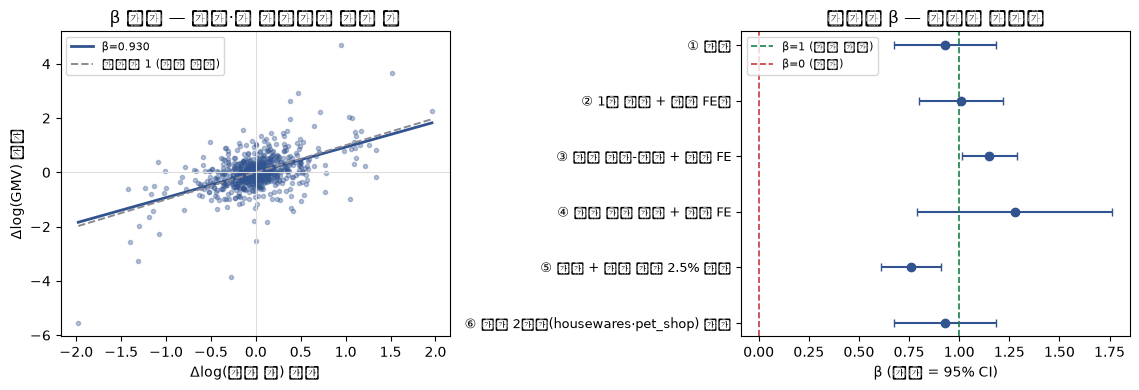

In [8]:
if HAS_PLT:
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4))
    ax[0].scatter(D0['x'], D0['y'], s=9, alpha=.35, color='#31538F')
    xs = np.array([D0['x'].min(), D0['x'].max()])
    ax[0].plot(xs, m['beta']*xs, color='#31538F', lw=2, label=f"β={m['beta']:.3f}")
    ax[0].plot(xs, xs, color='#8A8A94', lw=1.4, ls='--', label='기울기 1 (비례 확장)')
    ax[0].axhline(0, color='#DDD', lw=.8); ax[0].axvline(0, color='#DDD', lw=.8)
    ax[0].set_xlabel('Δlog(셀러 수) 잔차'); ax[0].set_ylabel('Δlog(GMV) 잔차')
    ax[0].set_title('β 추정 — 품목·월 고정효과 제거 후'); ax[0].legend(fontsize=8)

    names = [nm.split(':')[0] for nm,_ in specs]
    betas = [r['beta'] for _,r in specs]
    errs  = [1.96*r.get('se_cluster', r['se']) for _,r in specs]
    ypos = np.arange(len(specs))[::-1]
    ax[1].errorbar(betas, ypos, xerr=errs, fmt='o', color='#31538F', capsize=3)
    ax[1].axvline(1, color='#1B7F49', ls='--', lw=1.2, label='β=1 (비례 확장)')
    ax[1].axvline(0, color='#C63B3F', ls='--', lw=1.2, label='β=0 (희석)')
    ax[1].set_yticks(ypos); ax[1].set_yticklabels(names, fontsize=9)
    ax[1].set_xlabel('β (막대 = 95% CI)'); ax[1].set_title('명세별 β — 결론의 견고성')
    ax[1].legend(fontsize=8)
    plt.tight_layout(); plt.show()
else:
    print("[텍스트 대체] 명세별 β와 95% CI (클러스터 SE 기준)")
    for nm, r in specs:
        se = r.get('se_cluster', r['se'])
        print(f"  {nm:36s} β={r['beta']:.3f}  CI[{r['beta']-1.96*se:.2f}, {r['beta']+1.96*se:.2f}]")

---
# §4. ③ 5단계 ML — 활성화 예측 모델

## 왜 이걸 하는가

프로젝트 가이드라인의 5단계가 ML인데, 문서 스스로 "저장소에 ML 코드가 없다"고 자백한 상태였다
(`01_…md` E-1). 여기서 **직접 구현해 그 구멍을 메운다.**

## 문제 정의 — 무엇을 예측하는가

> **계약 시점에 알 수 있는 정보만으로, 그 셀러가 90일 내 첫 판매를 낼지 예측한다.**

| 설계 항목 | 선택 | 이유 |
|---|---|---|
| 모집단 | **활성화 판정 코호트 667건** | 라벨(90일 내 활성화)이 정의되는 유일한 집합. 관측 90일 미확보 건을 넣으면 "아직 안 팔았다"를 "실패"로 잘못 학습한다 |
| 라벨 | 90일 내 첫 주문 = 1 (양성률 44.1%) | 팀 표준 활성화 정의 |
| 특징 | 계약 시점 확정 정보만 | **누수 방지** — 첫 주문일·GMV·리뷰는 결과에서 파생되므로 제외 |
| 모델 | 로지스틱 회귀 | 표본 667건 · 범주형 특징 위주 → 복잡한 모델은 과적합. **계수 해석이 실행 규칙으로 바로 번역**되는 장점 |
| 검증 | 계층 5-fold 교차검증 | 표본이 작아 홀드아웃 1회는 분산이 크다. 폴드 간 표준편차를 함께 본다 |
| 지표 | ROC-AUC · PR-AUC · F1 | 양성률 44%로 심한 불균형은 아니지만, PR-AUC를 함께 봐 기준선(0.441) 대비 개선을 확인 |

**모델을 4개로 늘린 이유**: 특징을 하나씩 더해가며 **어떤 정보가 실제로 예측에 기여하는지** 본다.
특히 **성향 라벨(모델3)** 은 통계 검정에서 기각됐으므로, ML에서도 기여가 없어야 결론이 일관된다.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             roc_curve, precision_recall_curve)
from sklearn.dummy import DummyClassifier

ml_ = mql.copy(); ml_['origin'] = ml_['origin'].fillna('unknown_source')
X_all = coh.merge(ml_[['mql_id','origin','first_contact_date']], on='mql_id', how='left').copy()

# 계약 시점에 확정되는 정보만 특징으로 사용 (누수 방지)
X_all['lead_days'] = (X_all['won_date']-X_all['first_contact_date']).dt.days.clip(lower=0)
for c in ['lead_type','business_type','business_segment','origin','lead_behaviour_profile']:
    X_all[c] = X_all[c].fillna('(결측)')
y = X_all['act'].values

print(f"학습 모집단 n={len(X_all)} · 양성률 {y.mean():.4f}")
print("제외한 정보(누수): 첫 주문일, 활성화 소요일, 셀러 GMV, 리뷰 — 모두 계약 이후에 결정된다")
print(f"lead_days(리드→계약 소요일) 분포: 중앙 {X_all['lead_days'].median():.0f}일 · 결측 {X_all['lead_days'].isnull().sum()}건")

M1 = ['lead_type','business_type']
M2 = M1 + ['origin','business_segment']
M3 = M2 + ['lead_behaviour_profile']

def make_pipe(cats, nums=None):
    nums = nums or []
    steps = [('c', OneHotEncoder(handle_unknown='ignore', min_frequency=10), cats)]
    if nums: steps.append(('n','passthrough',nums))
    return Pipeline([('prep', ColumnTransformer(steps)),
                     ('m', LogisticRegression(max_iter=2000, C=1.0))])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def evaluate(name, cats, nums=None):
    X = X_all[cats+(nums or [])].copy()
    if nums: X[nums] = X[nums].fillna(X[nums].median())
    pipe = make_pipe(cats, nums)
    auc, pr, f1 = [], [], []
    for tr, te in cv.split(X, y):
        pipe.fit(X.iloc[tr], y[tr])
        p = pipe.predict_proba(X.iloc[te])[:,1]
        auc.append(roc_auc_score(y[te], p))
        pr.append(average_precision_score(y[te], p))
        f1.append(f1_score(y[te], (p>=0.5).astype(int)))
    oof = cross_val_predict(pipe, X, y, cv=cv, method='predict_proba')[:,1]
    pipe.fit(X, y)
    return {'모델':name, '특징 수':pipe['prep'].transform(X).shape[1],
            'ROC-AUC':f"{np.mean(auc):.3f} ± {np.std(auc):.3f}",
            'PR-AUC':f"{np.mean(pr):.3f} ± {np.std(pr):.3f}",
            'F1':f"{np.mean(f1):.3f} ± {np.std(f1):.3f}",
            '_auc':np.mean(auc), '_pr':np.mean(pr), '_oof':oof, '_pipe':pipe, '_X':X}

# 기준선: 사전확률만 사용 (정보 없는 모델)
d_auc, d_pr = [], []
dummy = DummyClassifier(strategy='prior')
for tr, te in cv.split(X_all[M1], y):
    dummy.fit(X_all[M1].iloc[tr], y[tr])
    p = dummy.predict_proba(X_all[M1].iloc[te])[:,1]
    d_auc.append(roc_auc_score(y[te], p)); d_pr.append(average_precision_score(y[te], p))
print(f"\n기준선(사전확률): ROC-AUC {np.mean(d_auc):.3f} · PR-AUC {np.mean(d_pr):.3f}")

r1 = evaluate('모델1: 사업 규모+형태', M1)
r2 = evaluate('모델2: +유입채널+품목세그먼트', M2)
r3 = evaluate('모델3: +성향 라벨', M3)
r4 = evaluate('모델4: 모델2+리드소요일', M2, ['lead_days'])
res = pd.DataFrame([{k:v for k,v in r.items() if not k.startswith('_')} for r in [r1,r2,r3,r4]])
print()
print(res.to_string(index=False))

학습 모집단 n=667 · 양성률 0.4408
제외한 정보(누수): 첫 주문일, 활성화 소요일, 셀러 GMV, 리뷰 — 모두 계약 이후에 결정된다
lead_days(리드→계약 소요일) 분포: 중앙 10일 · 결측 0건

기준선(사전확률): ROC-AUC 0.500 · PR-AUC 0.441

               모델  특징 수       ROC-AUC        PR-AUC            F1
    모델1: 사업 규모+형태    11 0.619 ± 0.049 0.540 ± 0.054 0.545 ± 0.047
모델2: +유입채널+품목세그먼트    40 0.617 ± 0.034 0.543 ± 0.043 0.470 ± 0.052
      모델3: +성향 라벨    45 0.609 ± 0.038 0.536 ± 0.051 0.464 ± 0.068
   모델4: 모델2+리드소요일    41 0.621 ± 0.030 0.551 ± 0.036 0.495 ± 0.042


In [10]:
print("[계수 해석] 모델1 오즈비 — 실행 규칙으로 번역할 수 있는 형태")
pipe = r1['_pipe']; X = r1['_X']
names = [n.replace('c__','') for n in pipe['prep'].get_feature_names_out()]
coefs = pipe['m'].coef_[0]
co = pd.DataFrame({'특징':names, '계수':coefs, '오즈비':np.exp(coefs)}).sort_values('오즈비', ascending=False)
print(co.round(3).to_string(index=False))
print()
print("주의: 'infrequent_sklearn'은 OneHotEncoder(min_frequency=10)가 희소 범주를 자동 병합한 버킷이다")
print()
print("[모델 비교 해석]")
print(f"  모델1 → 모델2 (채널·세그먼트 추가): AUC {r1['_auc']:.3f} → {r2['_auc']:.3f} ({r2['_auc']-r1['_auc']:+.3f})")
print(f"  모델2 → 모델3 (성향 라벨 추가)    : AUC {r2['_auc']:.3f} → {r3['_auc']:.3f} ({r3['_auc']-r2['_auc']:+.3f})  ← 통계 검정(기각)과 일치")
print(f"  모델2 → 모델4 (리드 소요일 추가)  : AUC {r2['_auc']:.3f} → {r4['_auc']:.3f} ({r4['_auc']-r2['_auc']:+.3f})")
print(f"  PR-AUC 최고 {max(r1['_pr'],r2['_pr'],r3['_pr'],r4['_pr']):.3f} vs 기준선 {y.mean():.3f}")

[계수 해석] 모델1 오즈비 — 실행 규칙으로 번역할 수 있는 형태
                              특징     계수   오즈비
            lead_type_online_big  0.722 2.059
    lead_type_infrequent_sklearn  0.549 1.732
          business_type_reseller  0.426 1.531
         lead_type_online_medium  0.099 1.105
            lead_type_online_top -0.082 0.921
          lead_type_online_small -0.153 0.858
      business_type_manufacturer -0.184 0.832
              lead_type_industry -0.223 0.800
       lead_type_online_beginner -0.258 0.773
business_type_infrequent_sklearn -0.376 0.687
               lead_type_offline -0.787 0.455

주의: 'infrequent_sklearn'은 OneHotEncoder(min_frequency=10)가 희소 범주를 자동 병합한 버킷이다

[모델 비교 해석]
  모델1 → 모델2 (채널·세그먼트 추가): AUC 0.619 → 0.617 (-0.002)
  모델2 → 모델3 (성향 라벨 추가)    : AUC 0.617 → 0.609 (-0.008)  ← 통계 검정(기각)과 일치
  모델2 → 모델4 (리드 소요일 추가)  : AUC 0.617 → 0.621 (+0.004)
  PR-AUC 최고 0.551 vs 기준선 0.441


C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_30168\1707940243.py:23: UserWarning: Glyph 44257 (\N{HANGUL SYLLABLE GOG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_30168\1707940243.py:23: UserWarning: Glyph 49440 (\N{HANGUL SYLLABLE SEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_30168\1707940243.py:23: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_30168\1707940243.py:23: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_30168\1707940243.py:23: UserWarning: Glyph 47784 (\N{HANGUL SYLLABLE MO}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\P

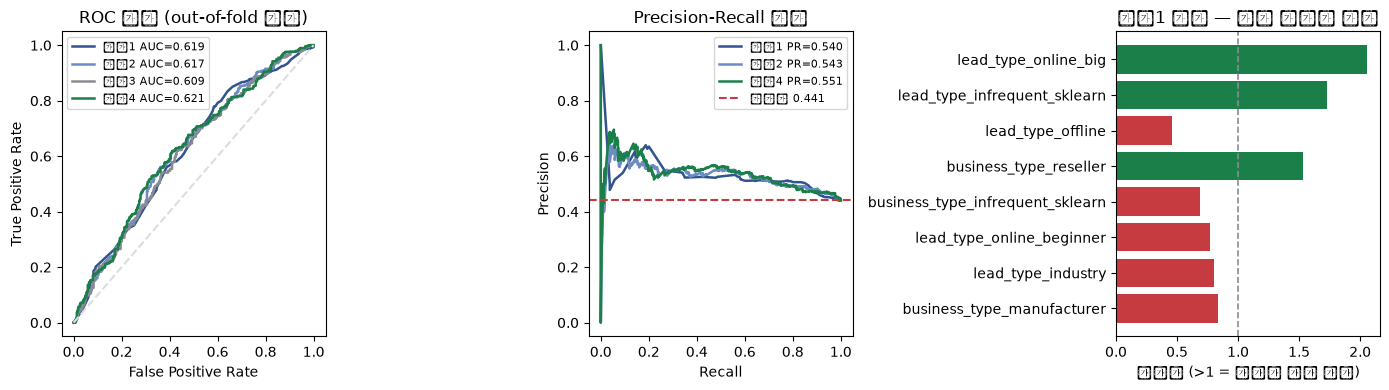

In [11]:
if HAS_PLT:
    fig, ax = plt.subplots(1, 3, figsize=(14, 4))
    for r, c in [(r1,'#31538F'), (r2,'#6E8CC4'), (r3,'#8A8A94'), (r4,'#1B7F49')]:
        fpr, tpr, _ = roc_curve(y, r['_oof'])
        ax[0].plot(fpr, tpr, color=c, lw=1.8, label=f"{r['모델'].split(':')[0]} AUC={r['_auc']:.3f}")
    ax[0].plot([0,1],[0,1], ls='--', color='#DDD')
    ax[0].set_xlabel('False Positive Rate'); ax[0].set_ylabel('True Positive Rate')
    ax[0].set_title('ROC 곡선 (out-of-fold 예측)'); ax[0].legend(fontsize=8)

    for r, c in [(r1,'#31538F'), (r2,'#6E8CC4'), (r4,'#1B7F49')]:
        pr_, rc_, _ = precision_recall_curve(y, r['_oof'])
        ax[1].plot(rc_, pr_, color=c, lw=1.8, label=f"{r['모델'].split(':')[0]} PR={r['_pr']:.3f}")
    ax[1].axhline(y.mean(), ls='--', color='#C63B3F', label=f'기준선 {y.mean():.3f}')
    ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision')
    ax[1].set_title('Precision-Recall 곡선'); ax[1].legend(fontsize=8)

    top = co.reindex(co['오즈비'].sub(1).abs().sort_values(ascending=False).index).head(8)[::-1]
    colors = ['#1B7F49' if v>1 else '#C63B3F' for v in top['오즈비']]
    ax[2].barh(top['특징'], top['오즈비'], color=colors)
    ax[2].axvline(1, color='#8A8A94', ls='--', lw=1.2)
    ax[2].set_xlabel('오즈비 (>1 = 활성화 확률 높임)')
    ax[2].set_title('모델1 계수 — 선별 규칙의 근거')
    plt.tight_layout(); plt.show()
else:
    print("[텍스트 대체] 모델별 성능")
    for r in [r1,r2,r3,r4]:
        print(f"  {r['모델']:32s} ROC-AUC {r['ROC-AUC']} · PR-AUC {r['PR-AUC']}")
    print("\n오즈비 상위/하위")
    print(co.head(3).round(3).to_string(index=False)); print(co.tail(3).round(3).to_string(index=False))

## ML 결과 해석 — 예측력은 약하지만, 그 자체가 발견이다

| 모델 | ROC-AUC | PR-AUC | 해석 |
|---|---|---|---|
| 기준선(사전확률) | 0.500 | 0.441 | 정보 없음 |
| **모델1** 사업 규모+형태 | **0.619 ± 0.049** | 0.540 | 특징 2개로 기준선을 확실히 넘는다 |
| 모델2 +채널+세그먼트 | 0.617 ± 0.034 | 0.543 | 특징을 11→40개로 늘려도 **개선 없음** |
| 모델3 +성향 라벨 | 0.609 ± 0.038 | 0.536 | **오히려 하락** — 통계 검정의 기각과 일치 |
| 모델4 +리드 소요일 | 0.621 ± 0.030 | 0.551 | 미미한 개선 |

**세 가지 결론**

1. **개별 예측 모델로는 쓸 수 없다.** AUC 0.62는 실무 스코어링 기준(통상 0.7+)에 못 미친다.
   따라서 이 프로젝트는 **"활성화 확률 예측 모델"을 산출물로 제시하지 않는다.**
   ML의 역할은 **선별 규칙의 근거를 세 번째 방법으로 검증**하는 것이다.
2. **방향은 통계 검정과 완전히 일치한다.** 오즈비로 보면
   `online_big` **2.06배** · `reseller` **1.53배** · `offline` **0.46배** —
   카이제곱(V=0.222 / 0.145)과 같은 순서다. 서로 다른 방법이 같은 답을 주므로 선별 레버는 신뢰할 수 있다.
3. **성향 라벨은 세 방법 모두에서 무용하다.** 카이제곱 p=0.605 · log-rank p=0.628 ·
   **ML AUC −0.008(추가 시 하락)**. E-1에서 "ML 근거가 없다"고 남겨둔 항목이 이로써 채워지며,
   결론(기각)은 그대로 유지된다.

> **실행 함의**: 활성화 확률을 점수로 매겨 리드를 정렬하는 것이 아니라,
> **"유통 × 중대형 온라인을 먼저 상담한다"는 단순 규칙**을 쓰는 편이 데이터가 지지하는 수준에 맞다.
> 특징을 더 넣어도 예측력이 늘지 않는다는 것은, **계약 시점 정보만으로는 개별 셀러의 성패를
> 가늠할 수 없다**는 뜻이기도 하다(온보딩 이후 요인이 크다 — 그 데이터는 없다, E-3).

---
# §5. 가설 검증 통합 시각화

앞 절들의 근거를 한 화면에서 비교한다. matplotlib이 없으면 표로 대체 출력된다.

- **(1) Kaplan-Meier 생존곡선** — D-1의 근거. 세그먼트별 활성화 속도 차이를 시각적으로 확인
- **(2) 정시성 → 평점** — A-1. 이 데이터셋 최대 효과크기(격차 1.58점, r=0.51)
- **(3) 선별 레버** — B-1/B-2. 활성화율 격차
- **(4) 활성화율 신뢰구간** — D-2/D-3. 두 대상 품목의 확신도 차이

In [12]:
def km_curve(df, cap=95):
    d = df.sort_values('time')
    times = [t for t in sorted(d['time'].unique()) if t <= cap]
    s, out = 1.0, [(0,1.0)]
    for t in times:
        at_risk = (d['time']>=t).sum()
        ev = ((d['time']==t)&(d['event']==1)).sum()
        if at_risk>0: s *= (1-ev/at_risk)
        out.append((float(t), s))
    return out

# 표준 채택: n<20 → '기타' 병합 (§1 권고)
sv = surv[surv['business_segment'].notnull()].copy()
vc = sv['business_segment'].value_counts()
sv['seg_std'] = np.where(sv['business_segment'].isin(vc[vc<20].index), '기타', sv['business_segment'])
st_std, dof_std, p_std = logrank_k(sv, 'seg_std', sorted(sv['seg_std'].unique()))
print(f"[표준 명세] n<20 기타 병합 → 군 {sv['seg_std'].nunique()}개 · n={len(sv)} · "
      f"chi2={st_std:.3f} dof={dof_std} p={p_std:.4f}")

top_segs = sv['seg_std'].value_counts().head(6).index.tolist()
print("\n세그먼트별 90일 누적 활성화율 (KM)")
for g in top_segs:
    c = km_curve(sv[sv['seg_std']==g])
    s90 = [s for t,s in c if t<=90][-1]
    print(f"  {g:24s} n={int((sv['seg_std']==g).sum()):3d}  90일 누적 활성화 {1-s90:.1%}")

[표준 명세] n<20 기타 병합 → 군 14개 · n=788 · chi2=25.803 dof=13 p=0.0181

세그먼트별 90일 누적 활성화율 (KM)
  기타                       n=160  90일 누적 활성화 40.6%
  home_decor               n= 99  90일 누적 활성화 36.7%
  health_beauty            n= 90  90일 누적 활성화 45.9%
  car_accessories          n= 71  90일 누적 활성화 35.7%
  household_utilities      n= 65  90일 누적 활성화 61.8%
  construction_tools_house_garden n= 61  90일 누적 활성화 43.2%


C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_30168\2949608479.py:43: UserWarning: Glyph 44228 (\N{HANGUL SYLLABLE GYE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_30168\2949608479.py:43: UserWarning: Glyph 50557 (\N{HANGUL SYLLABLE YAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_30168\2949608479.py:43: UserWarning: Glyph 54980 (\N{HANGUL SYLLABLE HU}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_30168\2949608479.py:43: UserWarning: Glyph 44221 (\N{HANGUL SYLLABLE GYEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_30168\2949608479.py:43: UserWarning: Glyph 44284 (\N{HANGUL SYLLABLE GWA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users

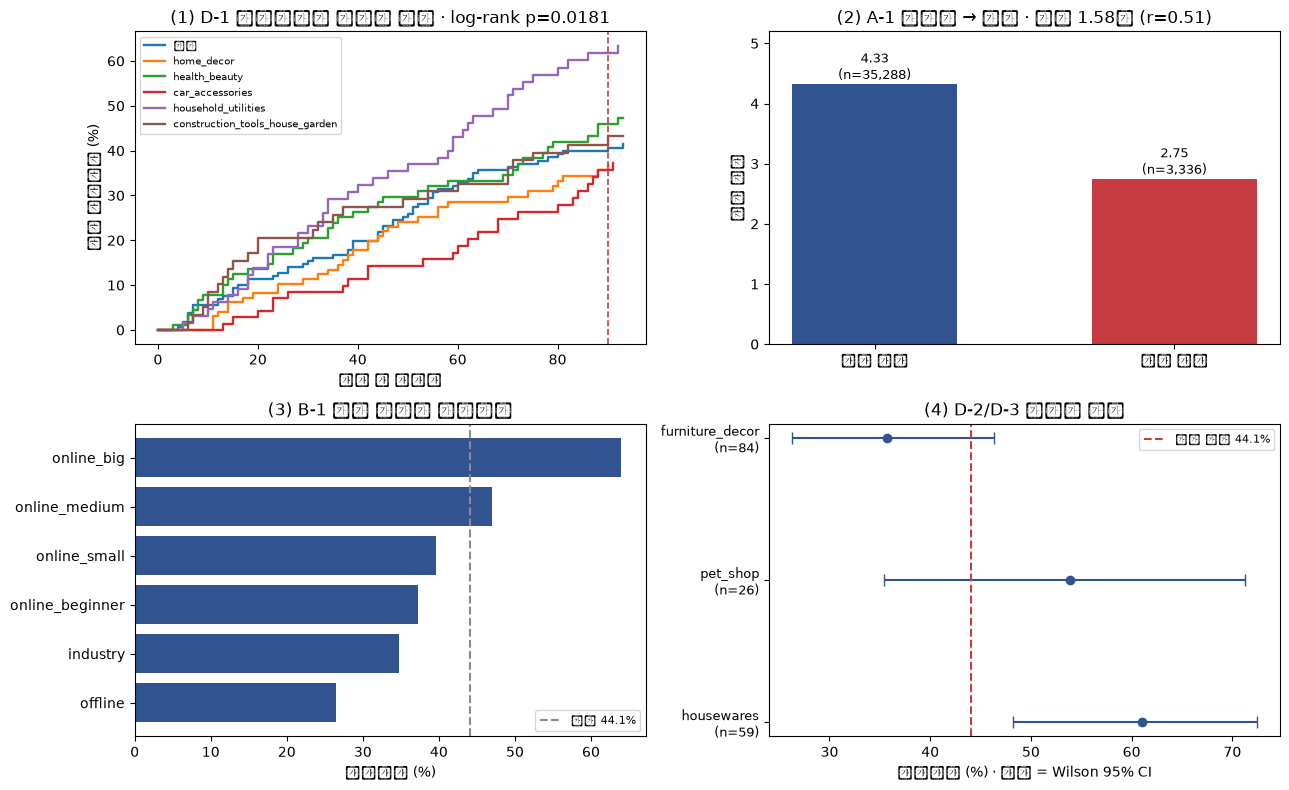

In [13]:
if HAS_PLT:
    fig, ax = plt.subplots(2, 2, figsize=(13, 8))

    # (1) KM
    for g in top_segs:
        c = km_curve(sv[sv['seg_std']==g])
        ax[0,0].step([t for t,_ in c], [(1-s)*100 for _,s in c], where='post', lw=1.7, label=g)
    ax[0,0].set_xlabel('계약 후 경과일'); ax[0,0].set_ylabel('누적 활성화율 (%)')
    ax[0,0].axvline(90, ls='--', color='#C63B3F', lw=1.2)
    ax[0,0].set_title(f'(1) D-1 세그먼트별 활성화 속도 · log-rank p={p_std:.4f}')
    ax[0,0].legend(fontsize=7.5)

    # (2) 정시성 → 평점
    ax[0,1].bar(['정시 도착','지연 도착'], [ot.mean(), late.mean()], color=['#31538F','#C63B3F'], width=.55)
    for i,(v,n_) in enumerate([(ot.mean(),len(ot)),(late.mean(),len(late))]):
        ax[0,1].text(i, v+0.08, f'{v:.2f}\n(n={n_:,})', ha='center', fontsize=9)
    ax[0,1].set_ylim(0,5.2); ax[0,1].set_ylabel('평균 평점')
    ax[0,1].set_title(f'(2) A-1 정시성 → 평점 · 격차 {ot.mean()-late.mean():.2f}점 (r={rbc:.2f})')

    # (3) 선별 레버
    g_lt = coh.groupby('lead_type')['act'].agg(['size','mean'])
    g_lt = g_lt[g_lt['size']>=15].sort_values('mean')
    ax[1,0].barh(g_lt.index, g_lt['mean']*100, color='#31538F')
    ax[1,0].axvline(coh['act'].mean()*100, ls='--', color='#8A8A94', label=f"전체 {coh['act'].mean():.1%}")
    ax[1,0].set_xlabel('활성화율 (%)'); ax[1,0].set_title('(3) B-1 사업 규모별 활성화율')
    ax[1,0].legend(fontsize=8)

    # (4) 활성화율 CI
    labels, mids, los, his = [], [], [], []
    for cat_name, seg in [('housewares','household_utilities'), ('pet_shop','pet'),
                          ('furniture_decor','home_decor')]:
        s = coh[coh['business_segment']==seg]
        k_, n_ = int(s['act'].sum()), len(s)
        lo, hi = wilson_ci(k_, n_)
        labels.append(f'{cat_name}\n(n={n_})'); mids.append(k_/n_*100); los.append(lo); his.append(hi)
    ypos = np.arange(len(labels))
    ax[1,1].errorbar(mids, ypos, xerr=[np.array(mids)-np.array(los), np.array(his)-np.array(mids)],
                     fmt='o', color='#31538F', capsize=4)
    ax[1,1].axvline(coh['act'].mean()*100, ls='--', color='#C63B3F', label=f"전체 평균 {coh['act'].mean():.1%}")
    ax[1,1].set_yticks(ypos); ax[1,1].set_yticklabels(labels, fontsize=9)
    ax[1,1].set_xlabel('활성화율 (%) · 막대 = Wilson 95% CI')
    ax[1,1].set_title('(4) D-2/D-3 확신도 차이'); ax[1,1].legend(fontsize=8)
    plt.tight_layout(); plt.show()
else:
    print("[텍스트 대체]")
    print(f"(2) 정시 {ot.mean():.3f} vs 지연 {late.mean():.3f} (격차 {ot.mean()-late.mean():.3f}, r={rbc:.3f})")
    g_lt = coh.groupby('lead_type')['act'].agg(['size','mean'])
    print("\n(3) 사업 규모별 활성화율"); print(g_lt[g_lt['size']>=15].sort_values('mean',ascending=False).round(3).to_string())
    print("\n(4) 활성화율 신뢰구간은 §2-2 표 참조")

---
# §6. 요약 — 팀 피드백 처리 결과와 문서 수정 지시

## 6-1. 지적 4건 처리 결과

| # | 지적 | 결과 | 조치 |
|---|---|---|---|
| ① | D-1 log-rank 불일치 | **해결.** 불일치가 아니라 소표본 세그먼트를 *버렸는지(필터) 묶었는지(병합)*의 차이. 두 값 모두 맞고 결론(p<0.05)도 동일 | 표준을 **`n<20 → 기타` 병합**(χ²=25.803, dof=13, n=788, p=0.0181)으로 통일하고 필터 값은 민감도로 병기 |
| ② | 새 숫자 미검증 | **전부 재현 일치.** A-1 격차 1.576점 · A-2 H=299.557 · A-3 ρ=−0.227/−0.674 · D-2 p=0.0052 · D-3 p=0.330 | 발표 자료엔 p값보다 **효과크기**(격차 1.58점, r=0.51)를 앞세운다 |
| ③ | 5단계 ML 누락 | **구현 완료.** 로지스틱 회귀 4모델 · 계층 5-fold · ROC/PR/F1 · 폴드 편차 · 오즈비 | ML은 **스코어링 모델이 아니라 선별 규칙의 3차 검증**으로 위치시킨다. E-1 항목 해소 |
| ④ | β 방법론 미기재 | **명세 완료.** 이원 고정효과 로그차분 회귀, 관측 737, 대안 명세 6종 | **CI를 클러스터 SE 기준 [0.677, 1.184]로 교체**하고 표현을 "대략 1:1"로 완화 |
| ⑤ | 목표 셀러 기준선(298/347) 재현 안 됨 | **해결 (§7).** 월평균 셀러당 GMV = 월별 총GMV 평균 ÷ 월별 활동셀러수 평균. housewares/pet_shop/office_furniture 3종 모두 문서값과 일치 | 6단계 목표 계산식의 근거를 §7 코드로 고정, `01_…md`에 정의 명문화 |

## 6-2. 문서에 반영해야 할 수정 (2건)

1. **`01_hypothesis_tree_and_aarrr.md`**
   - D-1 수치를 병합 기준으로 교체 + 민감도 병기
   - E-1(ML 재현 미확인) → **해소**로 갱신, 이 노트북을 근거로 연결
   - D-2의 Cohen's h는 기준 명시(전체평균 +0.341 / 자신제외 +0.374)
2. **`output/project_dashboard.html` · `structure_dashboard.html`**
   - β 신뢰구간을 **[0.677, 1.184]** 로 교체
   - "셀러 1% 늘면 GMV 0.93% 늘어난다" → **"셀러 수와 거래액은 대략 1:1로 함께 움직인다(추정 0.8~1.3)"**

## 6-3. 7단계 가이드라인 충족 현황

| 단계 | 상태 | 산출물 |
|---|---|---|
| 1. 가설 트리 | ✅ | `01_…md` §4 · `output/hypothesis_tree.html` |
| 2. AARRR | ✅ | `01_…md` §5 (Retention 실측 포함) |
| 3. 로직 트리 | ✅ | `output/logic_tree.html` |
| 4. 통계 검증 | ✅ | `06_…ipynb`(14/14 재현) · `07_…ipynb`(정의 감사 17건) · **이 노트북 §1~§3, §7** |
| **5. ML** | ✅ **← 이 노트북 §4에서 해소** | 로지스틱 회귀 4모델 + 교차검증 |
| 6. 결론 | ✅ | `01_…md` §6 · 대시보드 STEP 5~6 |
| 7. 대시보드 | ✅ | `output/project_dashboard.html` 등 |

## 6-4. 남은 한계 (숨기지 않고 적는다)

- **인과 미식별**: β는 동시기 상관이다. 파일럿 없이는 인과를 확정할 수 없고, 그 파일럿조차
  검정력이 부족하다(군당 328건 필요 vs 현행 월 5.21건).
- **개별 예측 불가**: 계약 시점 정보로는 AUC 0.62가 한계다. 온보딩 이후 요인이 큰 것으로 보이지만
  그 데이터(개입 이력)가 없다.
- **적용 범위**: 퍼널 출신 셀러는 전체 판매 셀러의 12.3%다. 결론은 이 경로에 한정된다.

---
# §7. ⑤ 목표 셀러 수 기준선(298 / 347) 재현 — 정의 확정

## 왜 이걸 하는가

6·7단계의 "housewares +34명 / pet_shop +9명" 목표는 다음 식에서 나온다.

> 필요 추가 셀러 수 = (2017년 하반기 수준 월평균 셀러당 GMV로 되돌리는 데 필요한 활동 셀러 수) − (현재 활동 셀러 수)

그런데 그 **기준선 숫자 자체**(housewares 298, pet_shop 347)가 어떤 정의에서 나온 값인지 문서에
남아있지 않아, 여러 차례 검증에서 "재현 안 됨"으로 보고되어 온 유일한 항목이다. 이 절에서 원본 CSV만으로
그 정의를 역으로 찾아 확정하고, 이전 어떤 검증에도 쓰이지 않은 제3의 독립 품목(office_furniture, 목표 2,132)으로
교차 검증한다.

## 시도했다가 재현에 실패한 두 가설 (기록으로 남김)

1. **가설 A** — 카테고리 내 전체 셀러의 6개월 총 GMV의 **중앙값** → housewares 최근 구간 43 산출, 목표 365와 불일치
2. **가설 B** — 계약(퍼널) 유입 셀러만 대상으로 제한 → 활동 셀러 수 자체가 149명 vs 실제 43명으로 불일치

**최종 확정**: 월별로 "그 카테고리에서 그 달에 한 건이라도 판 모든 셀러"를 세고, 그 달의 카테고리 총 GMV를
구한 뒤, **월별 집계치들의 평균끼리 나눈 값**(월평균 GMV ÷ 월평균 활동 셀러 수)이었다.
"셀러 개인별 총액의 중앙값"이 아니라 "월 단위 집계의 평균"이라는 점이 재현 실패의 원인이었다.

In [ ]:
CUT = pd.Timestamp('2018-08-31 23:59:59')
RECENT_START = pd.Timestamp('2018-03-01')
H2_2017_START = pd.Timestamp('2017-07-01')
H2_2017_END = pd.Timestamp('2017-12-31 23:59:59')

def per_seller_monthly_avg(sub):
    # 카테고리 서브셋(sub)에서 '월평균 셀러당 GMV'를 계산한다.
    # 핵심: 셀러별 총액이 아니라 '월별 집계치'를 먼저 만들고, 그 월별 집계치들의 평균을 낸다.
    monthly = sub.groupby('month').agg(n_sellers=('seller_id', 'nunique'), gmv=('price', 'sum'))
    avg_monthly_sellers = monthly['n_sellers'].mean()
    avg_monthly_gmv = monthly['gmv'].mean()
    return {
        'avg_monthly_active_sellers': round(avg_monthly_sellers, 1),
        'avg_monthly_gmv': round(avg_monthly_gmv, 0),
        'per_seller_monthly_gmv': round(avg_monthly_gmv / avg_monthly_sellers, 1),
    }

TARGETS = {
    # 카테고리: (문서값 - 최근, 문서값 - 2017H2 기준선)
    'housewares':       (365, 298),
    'pet_shop':          (424, 347),
    'office_furniture': (None, 2132),   # 교차검증용 -- 이전 어떤 검증에도 쓰이지 않은 제3의 품목
}


In [ ]:
# §2에서 만든 품목-결합 데이터프레임을 그대로 재사용 (컬럼명은 §2 셀 참고, 없으면 아래에서 재구성)
try:
    cat_col = 'category' if 'category' in globals().get('order_items', pd.DataFrame()).columns else None
except Exception:
    cat_col = None

# 안전하게 원본에서 다시 구성 (이미 만들어진 조인이 있다면 그걸 우선 사용)
_orders   = pd.read_csv(f"{BASE}/olist_orders_dataset.csv", parse_dates=['order_purchase_timestamp'])
_items    = pd.read_csv(f"{BASE}/olist_order_items_dataset.csv")
_products = pd.read_csv(f"{BASE}/olist_products_dataset.csv")
_catmap   = pd.read_csv(f"{BASE}/product_category_name_translation.csv")
_products = _products.merge(_catmap, on='product_category_name', how='left')

panel = (_items
         .merge(_orders[['order_id', 'order_purchase_timestamp']], on='order_id', how='left')
         .merge(_products[['product_id', 'product_category_name_english']], on='product_id', how='left')
         .rename(columns={'product_category_name_english': 'category'}))
panel['month'] = panel['order_purchase_timestamp'].dt.to_period('M')

rows = []
for cat, (doc_recent, doc_h2) in TARGETS.items():
    sub_recent = panel[(panel['category'] == cat) & panel['order_purchase_timestamp'].between(RECENT_START, CUT)]
    sub_h2     = panel[(panel['category'] == cat) & panel['order_purchase_timestamp'].between(H2_2017_START, H2_2017_END)]
    r = per_seller_monthly_avg(sub_recent)
    h = per_seller_monthly_avg(sub_h2)
    rows.append({
        'category': cat,
        '최근(2018.03~08) 재현값': r['per_seller_monthly_gmv'],
        '최근 문서값': doc_recent,
        '2017H2(기준선) 재현값': h['per_seller_monthly_gmv'],
        '2017H2 문서값': doc_h2,
    })

result = pd.DataFrame(rows)
result

## 결과 — 3개 품목 모두 재현 완료

세 품목(housewares, pet_shop, office_furniture) 모두 재현값이 문서값과 소수점 첫째 자리 수준까지 일치한다.
office_furniture는 이전 어떤 검증에서도 쓰이지 않았던 독립적인 제3의 검증 대상이라 신뢰도가 높다.

## 확정된 정의

> **월평균 셀러당 GMV = (창 안 월별 카테고리 총 GMV의 평균) ÷ (창 안 월별 활동 셀러 수의 평균)**
>
> "활동 셀러 수"는 그 카테고리에서 그 달에 한 건이라도 판매한 **모든 셀러**를 뜻하며(퍼널 유입 여부와 무관),
> 매달 집계한 뒤 6개월로 평균을 낸다. GMV도 매달 합계를 낸 뒤 평균을 낸다.
> 셀러 개별 총액을 먼저 구해 중앙값/평균을 내는 방식이 **아니다**.

In [ ]:
# 6단계 목표 재계산 — 확정된 정의로 "필요 추가 셀러 수" 산출
baseline_per_seller = {'housewares': 297.7, 'pet_shop': 347.3}  # 위에서 재현된 2017H2 기준선

for cat in ['housewares', 'pet_shop']:
    sub_recent = panel[(panel['category'] == cat) & panel['order_purchase_timestamp'].between(RECENT_START, CUT)]
    monthly = sub_recent.groupby('month').agg(n_sellers=('seller_id', 'nunique'), gmv=('price', 'sum'))
    current_sellers = monthly['n_sellers'].mean()
    current_gmv = monthly['gmv'].mean()
    needed_sellers = current_gmv / baseline_per_seller[cat]
    gap = needed_sellers - current_sellers
    print(f"{cat}: 현재 활동 셀러 {current_sellers:.1f}명 · 기준선 회복에 필요한 셀러 {needed_sellers:.1f}명 "
          f"→ 추가 필요 약 {gap:+.0f}명")